<a href="https://colab.research.google.com/github/hubertwojcik/deep_learning/blob/main/1_ANN_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [91]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

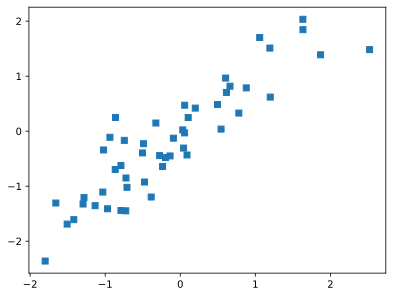

In [92]:
# Create data
N = 50
x = torch.randn(N,1)
y = x + torch.randn(N,1) / 2

# plot
plt.plot(x,y,'s')
plt.show()

In [93]:
# build model
ANNreg = nn.Sequential(
    nn.Linear(1,1),
    nn.ReLU(),
    nn.Linear(1,1)
)

ANNreg

Sequential(
  (0): Linear(in_features=1, out_features=1, bias=True)
  (1): ReLU()
  (2): Linear(in_features=1, out_features=1, bias=True)
)

In [94]:
# learning rate
learning_rate = .05

# loss function
loss_fun = nn.MSELoss()

# optimizer
optimizer = torch.optim.SGD(ANNreg.parameters(), lr=learning_rate)

In [95]:
# train the model
num_epochs = 500
losses = torch.zeros(num_epochs)

for epoch in range(num_epochs):
  # forward
  y_hat = ANNreg(x)

  # compute loss
  loss = loss_fun(y_hat, y)
  losses[epoch] = loss

  # backprop
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

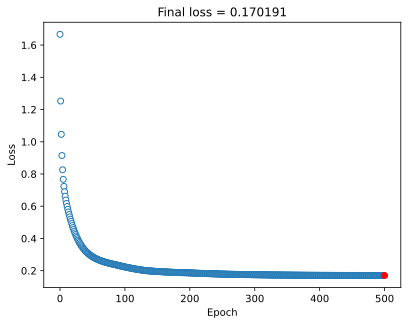

In [96]:
# show the losses

# manually compute losses
# final forward pass
predictions = ANNreg(x)

# final loss (MSE)
test_loss = (predictions-y).pow(2).mean()

plt.plot(losses.detach(),'o',markerfacecolor='w',linewidth=.1)
plt.plot(num_epochs,test_loss.detach(),'ro')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Final loss = %g' %test_loss.item())
plt.show()



In [97]:
test_loss.item()

0.17019136250019073

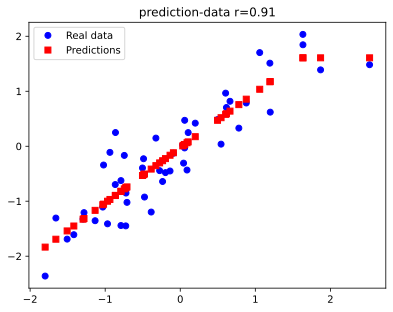

In [98]:
# plot the data
plt.plot(x,y,'bo',label='Real data')
plt.plot(x,predictions.detach(),'rs',label='Predictions')
plt.title(f'prediction-data r={np.corrcoef(y.T,predictions.detach().T)[0,1]:.2f}')
plt.legend()
plt.show()

